# Enron Preprocessing


In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


## 0. Install / upgrade dependencies

In [2]:
!pip install -q pyspellchecker language-tool-python swifter tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


## 1. Imports & configuration

In [3]:
import os, re, math, hashlib, warnings
import numpy as np
import pandas as pd
from collections import Counter
from multiprocessing import Pool, cpu_count

import nltk
for pkg in ['punkt', 'punkt_tab', 'stopwords', 'wordnet',
            'averaged_perceptron_tagger_eng']:
    nltk.download(pkg, quiet=True)

from nltk.corpus import stopwords as _sw
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk import pos_tag

import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

warnings.filterwarnings('ignore')

LEMMATIZER  = WordNetLemmatizer()
STOP_WORDS  = set(_sw.words('english'))
BITS        = 64

try:
    import torch
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
except ImportError:
    DEVICE = 'cpu'
print(f"Device : {DEVICE}")
print(f"CPU cores available : {cpu_count()}")

Device : cuda
CPU cores available : 2


## 2. Load Enron.csv

In [4]:
CSV_PATH = '/content/drive/MyDrive/Phishing_Email/datasets/Enron.csv'

df = pd.read_csv(CSV_PATH)
df['record_id'] = df.index

print("Shape :", df.shape)
print(df.dtypes)
df.head(2)

Shape : (29767, 4)
subject      object
body         object
label         int64
record_id     int64
dtype: object


,subject,body,label,record_id
0,"hpl nom for may 25 , 2001",( see attached file : hplno 525 . xls )\r\n- h...,0,0
1,re : nom / actual vols for 24 th,- - - - - - - - - - - - - - - - - - - - - - fo...,0,1


## 3. Inspect & validate

In [15]:
print("Columns       :", df.columns.tolist())
print("Label dist    :\n", df['label'].value_counts(dropna=False))
print("Missing vals  :\n", df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Columns       : ['subject', 'body', 'label', 'record_id', 'clean_text', 'has_attachment', 'word_count', 'avg_word_length', 'email_length', 'capital_letter_count', 'uppercase_ratio', 'exclamation_count', 'sentence_count', 'unique_word_ratio', 'text_density', 'digit_count', 'repeated_char_patterns', 'url_like_count', 'text_entropy']
Label dist    :
 label
0    14536
1    13720
Name: count, dtype: int64
Missing vals  :
 subject                   194
body                        0
label                       0
record_id                   0
clean_text                  0
has_attachment              0
word_count                  0
avg_word_length             0
email_length                0
capital_letter_count        0
uppercase_ratio             0
exclamation_count           0
sentence_count              0
unique_word_ratio           0
text_density                0
digit_count                 0
repeated_char_patterns      0
url_like_count              0
text_entropy                0
dtype: in

## 4. Clean labels

In [6]:
LABEL_MAP = {
    'spam': 1, 'phishing': 1, 'malicious': 1,
    'ham':  0, 'legitimate': 0, 'safe': 0,
}

if df['label'].dtype == object:
    df['label'] = df['label'].str.strip().str.lower().map(LABEL_MAP)

df['label'] = pd.to_numeric(df['label'], errors='coerce')
bad = df['label'].isna().sum()
if bad:
    print(f"Dropping {bad} rows with unrecognisable labels.")
    df = df.dropna(subset=['label'])

df['label'] = df['label'].astype(int)
print("Label dist after cleaning:\n", df['label'].value_counts())

Label dist after cleaning:
 label
0    15791
1    13976
Name: count, dtype: int64


## 5. Remove duplicates & missing-body rows

In [7]:
df.drop_duplicates(inplace=True)
df = df.dropna(subset=['body'])
df['body'] = df['body'].astype(str).str.strip()
df = df[df['body'].str.len() > 0].reset_index(drop=True)
print("Shape after body dedup:", df.shape)
print("Label dist:\n", df['label'].value_counts())

Shape after body dedup: (29767, 4)
Label dist:
 label
0    15791
1    13976
Name: count, dtype: int64


## 5b. Near-duplicate audit (intra-Enron, reporting only)

In [8]:
def simhash64(text, bits=BITS):
    tokens = str(text).lower().split()
    v = [0] * bits
    for token in tokens:
        h = int(hashlib.md5(token.encode()).hexdigest(), 16)
        for i in range(bits):
            v[i] += 1 if (h >> i) & 1 else -1
    return sum(1 << i for i in range(bits) if v[i] > 0)

print("Computing intra-Enron SimHashes for near-dup audit...")
_body_hashes = [simhash64(t) for t in tqdm(df['body'].tolist(), desc='SimHash')]

_seen, _nd = [], []
for _h in _body_hashes:
    if any(bin(_h ^ _s).count('1') <= 3 for _s in _seen):
        _nd.append(True)
    else:
        _seen.append(_h)
        _nd.append(False)

_n_nd = sum(_nd)
print(f"  Near-duplicate body rows : {_n_nd:,} / {len(df):,} ({_n_nd/len(df)*100:.1f}%)")


Computing intra-Enron SimHashes for near-dup audit...


SimHash:   0%|          | 0/29767 [00:00<?, ?it/s]

  Near-duplicate body rows : 7,574 / 29,767 (25.4%)


## 6. Text cleaning - vectorised where possible

In [9]:
_RE_URL   = re.compile(r'http\S+')
_RE_EMAIL = re.compile(r'\S+@\S+')
_RE_WS    = re.compile(r'\\s+')
_RE_ALPHA = re.compile(r'[^a-zA-Z ]')

def clean_text(text):
    text = str(text).lower()
    text = _RE_URL.sub(' URL ', text)
    text = _RE_EMAIL.sub(' EMAIL ', text)
    text = _RE_WS.sub(' ', text).strip()
    text = _RE_ALPHA.sub('', text)
    words = word_tokenize(text)
    words = [w for w in words if w not in STOP_WORDS]
    words = [LEMMATIZER.lemmatize(w) for w in words]
    return ' '.join(words)

try:
    import swifter
    print("Applying clean_text via swifter (parallel)...")
    df['clean_text'] = df['body'].swifter.apply(clean_text)
except ImportError:
    print("swifter not available - using pandas apply (single-core)...")
    df['clean_text'] = df['body'].apply(clean_text)

print("Done.")
df[['body', 'clean_text']].head(2)

Applying clean_text via swifter (parallel)...


Pandas Apply:   0%|          | 0/29767 [00:00<?, ?it/s]

Done.


,body,clean_text
0,( see attached file : hplno 525 . xls )\r\n- h...,see attached file hplno xl hplno xl
1,- - - - - - - - - - - - - - - - - - - - - - fo...,forwarded sabrae zajac hou ect pm enron capita...


## 7. Drop duplicates on clean_text

In [10]:
df = df.drop_duplicates(subset=['clean_text']).reset_index(drop=True)
print("Shape after clean_text dedup:", df.shape)
print("Label dist:\n", df['label'].value_counts())


Shape after clean_text dedup: (28308, 5)
Label dist:
 label
0    14542
1    13766
Name: count, dtype: int64


## 7b. AVN ↔ Enron cross-corpus decontamination (Hamming d ≤ 3)


In [11]:
AVN_PATH = '/content/drive/MyDrive/Phishing_Email/final_dataset/nlp_final_features.csv'
avn_df   = pd.read_csv(AVN_PATH, usecols=['clean_text', 'label'])
print(f"AVN rows loaded : {len(avn_df):,}")

def simhash64(text, bits=BITS):
    tokens = str(text).lower().split()
    v = [0] * bits
    for token in tokens:
        h = int(hashlib.md5(token.encode()).hexdigest(), 16)
        for i in range(bits):
            v[i] += 1 if (h >> i) & 1 else -1
    return sum((1 << i) for i in range(bits) if v[i] > 0)

def hamming(a, b):
    return bin(a ^ b).count('1')

print("Hashing AVN clean_text ...")
avn_hashes  = [simhash64(t) for t in tqdm(avn_df['clean_text'], desc='AVN')]
print("Hashing Enron clean_text ...")
enron_hashes = [simhash64(t) for t in tqdm(df['clean_text'],     desc='Enron')]

avn_hash_set = set(avn_hashes)
avn_hash_list = list(avn_hash_set)

print(f"Unique AVN hashes : {len(avn_hash_set):,}")
print("Running decontamination sweep (Hamming d<=3, linear scan)...")

is_near_dup = []
for enron_h in tqdm(enron_hashes, desc='Decontamination'):
    if enron_h in avn_hash_set:
        is_near_dup.append(True)
        continue
    found = any(hamming(enron_h, a) <= 3 for a in avn_hash_list)
    is_near_dup.append(found)

n_overlap = sum(is_near_dup)
n_total   = len(df)
n_clean   = n_total - n_overlap

print()
print("=" * 62)
print("  AVN / Enron DECONTAMINATION REPORT")
print("=" * 62)
print(f"  Enron rows before decontamination : {n_total:,}")
print(f"  Near-duplicates (d<=3)              : {n_overlap:,}  ({n_overlap/n_total*100:.1f}%)")
print(f"  Rows removed                        : {n_overlap:,}")
print(f"  Clean rows remaining                : {n_clean:,}")
print("=" * 62)

df = df[~pd.Series(is_near_dup, index=df.index)].reset_index(drop=True)
print(f"\ndf after decontamination: {df.shape}")
print(df['label'].value_counts())

AVN rows loaded : 43,897
Hashing AVN clean_text ...


AVN:   0%|          | 0/43897 [00:00<?, ?it/s]

Hashing Enron clean_text ...


Enron:   0%|          | 0/28308 [00:00<?, ?it/s]

Unique AVN hashes : 43,515
Running decontamination sweep (Hamming d<=3, linear scan)...


Decontamination:   0%|          | 0/28308 [00:00<?, ?it/s]


  AVN / Enron DECONTAMINATION REPORT
  Enron rows before decontamination : 28,308
  Near-duplicates (d<=3)              : 52  (0.2%)
  Rows removed                        : 52
  Clean rows remaining                : 28,256

df after decontamination: (28256, 5)
label
0    14536
1    13720
Name: count, dtype: int64


## 8. Attachment detection

In [12]:
_RE_ATTACH = re.compile(
    r'\b(attach|attached|attachment|enclosed|pfa|see attached|find attached)\b'
    r'|\b\w+\.(pdf|docx|xlsx|zip|jpg|png)\b',
    re.IGNORECASE
)

df['has_attachment'] = df['body'].str.contains(_RE_ATTACH, regex=True).astype(int)
print("has_attachment dist:\n", df['has_attachment'].value_counts())
print("Attachment vs label:\n",  df.groupby('label')['has_attachment'].sum())

has_attachment dist:
 has_attachment
0    24871
1     3385
Name: count, dtype: int64
Attachment vs label:
 label
0    3002
1     383
Name: has_attachment, dtype: int64


## 9. Numerical feature engineering - fully vectorised

In [13]:
body = df['body'].astype(str)
ctxt = df['clean_text'].astype(str)

split_ctxt = ctxt.str.split()
df['word_count']      = split_ctxt.str.len()

df['avg_word_length'] = (
    ctxt.str.replace(r'\s+', '', regex=True).str.len()
    / df['word_count'].replace(0, np.nan)
).fillna(0)

df['email_length'] = body.str.len()

df['capital_letter_count'] = body.apply(lambda x: sum(1 for c in x if c.isupper()))
df['uppercase_ratio']      = df['capital_letter_count'] / (df['email_length'] + 1)

df['exclamation_count'] = body.str.count('!')
df['sentence_count']    = body.str.count(r'[.!?]')

df['unique_word_ratio'] = split_ctxt.apply(
    lambda ws: len(set(ws)) / (len(ws) + 1) if ws else 0
)

df['text_density'] = df['word_count'] / (df['email_length'] + 1)

df['digit_count'] = body.str.count(r'\d')

df['repeated_char_patterns'] = body.str.count(r'(.)\1{2,}')

_RE_URL_LIKE = re.compile(r'(www|http|\.com|\.net|\.org)', re.IGNORECASE)
df['url_like_count'] = body.str.count(_RE_URL_LIKE)

def _entropy(text):
    if not text:
        return 0.0
    freq  = Counter(text)
    n     = len(text)
    probs = np.array(list(freq.values())) / n
    return float(-np.dot(probs, np.log2(probs + 1e-12)))

df['text_entropy'] = body.apply(_entropy)

print("Numerical features added.")
print(df[['word_count','avg_word_length','uppercase_ratio',
          'url_like_count','text_entropy']].describe())

Numerical features added.
         word_count  avg_word_length  uppercase_ratio  url_like_count  \
count  28256.000000     28256.000000          28256.0    28256.000000   
mean     136.055316         6.249049              0.0        0.579523   
std      393.880042         1.348039              0.0        3.135806   
min        0.000000         0.000000              0.0        0.000000   
25%       32.000000         5.666667              0.0        0.000000   
50%       64.000000         6.174242              0.0        0.000000   
75%      142.000000         6.710910              0.0        0.000000   
max    20953.000000        97.200000              0.0      249.000000   

       text_entropy  
count  28256.000000  
mean       4.386105  
std        0.202856  
min        1.000000  
25%        4.306340  
50%        4.401759  
75%        4.498158  
max        5.064769  


In [14]:
body_raw = df["body"].astype(str)

n_with_upper = body_raw.str.contains(r"[A-Z]", regex=True).sum()
total_upper  = body_raw.apply(lambda x: sum(c.isupper() for c in x)).sum()

print("=" * 62)
print("  UPPERCASE_RATIO AUDIT")
print("=" * 62)
print(f"  Emails with >=1 uppercase char : {n_with_upper:,} / {len(df):,}")
print(f"  Total uppercase characters     : {total_upper:,}")
print()
print("  uppercase_ratio distribution:")
print(df["uppercase_ratio"].describe().to_string())
print()
print("=" * 62)

  UPPERCASE_RATIO AUDIT
  Emails with >=1 uppercase char : 0 / 28,256
  Total uppercase characters     : 0

  uppercase_ratio distribution:
count    28256.0
mean         0.0
std          0.0
min          0.0
25%          0.0
50%          0.0
75%          0.0
max          0.0



## 10. Action density - batch POS tagging

In [17]:
def action_density_batch(text_series):
    texts     = text_series.fillna('').astype(str).str.lower().tolist()
    tokenized = [word_tokenize(t) for t in tqdm(texts, desc='Tokenising')]
    all_words = [w for doc in tokenized for w in doc]

    print(f"POS-tagging {len(all_words):,} tokens...")
    tagged = pos_tag(all_words)

    results, idx = [], 0
    for doc in tokenized:
        n = len(doc)
        if n == 0:
            results.append(0.0)
        else:
            verbs = sum(1 for _, tag in tagged[idx:idx+n] if tag.startswith('VB'))
            results.append(verbs / n)
        idx += n
    return results

print("Computing action_density...")
df['action_density'] = action_density_batch(df['body'])
print("Done.")
print(df['action_density'].describe())

Computing action_density...


Tokenising:   0%|          | 0/28256 [00:00<?, ?it/s]

POS-tagging 8,859,277 tokens...
Done.
count    28256.000000
mean         0.120433
std          0.050135
min          0.000000
25%          0.088496
50%          0.119403
75%          0.148649
max          1.000000
Name: action_density, dtype: float64


## 11a. Spelling error count - vectorised batch SpellChecker

In [18]:
from spellchecker import SpellChecker

spell = SpellChecker()

def spelling_errors_batch(series, text_limit=150):
    texts  = series.fillna('').astype(str).str[:text_limit].str.lower().tolist()
    tokens_per_row = [t.split() for t in texts]

    all_words  = {w for tokens in tokens_per_row for w in tokens}
    unknown    = spell.unknown(all_words)

    return [sum(1 for w in tokens if w in unknown) for tokens in tokens_per_row]

print("Computing spelling_error_count (batch, OOD-safe)...")
df['spelling_error_count'] = spelling_errors_batch(df['body'])
print("Done.")
print(df['spelling_error_count'].describe())

Computing spelling_error_count (batch, OOD-safe)...
Done.
count    28256.000000
mean         2.213654
std          2.576765
min          0.000000
25%          1.000000
50%          1.000000
75%          3.000000
max         27.000000
Name: spelling_error_count, dtype: float64


## 11b. Grammar error count - single LanguageTool process


In [19]:
import language_tool_python
from concurrent.futures import ThreadPoolExecutor, as_completed

_lt_tool = language_tool_python.LanguageTool('en-US')

def _grammar_count(text, limit=250):
    text = str(text)[:limit]
    if len(text) < 20 or text.isalpha():
        return 0
    try:
        return len(_lt_tool.check(text))
    except Exception:
        return 0

def grammar_errors_parallel(series, max_workers=4):
    texts   = series.fillna('').astype(str).tolist()
    results = [0] * len(texts)

    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        futures = {ex.submit(_grammar_count, t): i for i, t in enumerate(texts)}
        for fut in tqdm(as_completed(futures), total=len(texts),
                        desc='Grammar checking'):
            results[futures[fut]] = fut.result()
    return results

print("Computing grammar_error_count (threaded, single JVM)...")
df['grammar_error_count'] = grammar_errors_parallel(df['body'])
print("Done.")
print(df['grammar_error_count'].describe())

Computing grammar_error_count (threaded, single JVM)...


Grammar checking:   0%|          | 0/28256 [00:00<?, ?it/s]

Done.
count    28256.000000
mean        12.374788
std          6.150622
min          0.000000
25%          8.000000
50%         11.000000
75%         15.000000
max         50.000000
Name: grammar_error_count, dtype: float64


## 12. Build `nlp_final` feature table

In [20]:
KEEP_COLS = [
    'label', 'clean_text', 'word_count', 'avg_word_length',
    'uppercase_ratio', 'url_like_count', 'text_entropy',
    'action_density', 'grammar_error_count', 'spelling_error_count',
    'has_attachment', 'repeated_char_patterns',
]

nlp_final = df[KEEP_COLS].copy()

nlp_final['writing_error_total'] = (
    nlp_final['grammar_error_count'] + nlp_final['spelling_error_count']
)
nlp_final.drop(columns=['grammar_error_count', 'spelling_error_count'], inplace=True)

print("nlp_final shape:", nlp_final.shape)
nlp_final.head(2)

nlp_final shape: (28256, 11)


,label,clean_text,word_count,avg_word_length,uppercase_ratio,url_like_count,text_entropy,action_density,has_attachment,repeated_char_patterns,writing_error_total
0,0,see attached file hplno xl hplno xl,7,4.142857,0.0,0,4.112720,0.133333,1,0,12
1,0,forwarded sabrae zajac hou ect pm enron capita...,144,4.944444,0.0,0,4.604621,0.053991,0,1,16


## 13. Correlation check

In [21]:
num_feats = nlp_final.select_dtypes(include='number').drop(columns=['label'])
corr_mat  = num_feats.corr()

threshold  = 0.8
corr_pairs = [
    (corr_mat.columns[i], corr_mat.columns[j], round(corr_mat.iloc[i, j], 4))
    for i in range(len(corr_mat.columns))
    for j in range(i + 1, len(corr_mat.columns))
    if abs(corr_mat.iloc[i, j]) > threshold
]
corr_pairs.sort(key=lambda x: abs(x[2]), reverse=True)
print("Highly correlated pairs (|r| > 0.8):", corr_pairs or 'None')

Highly correlated pairs (|r| > 0.8): None


## 14. Data quality checks

In [22]:
num_cols = nlp_final.select_dtypes(include=[np.number]).columns

inf_counts = nlp_final[num_cols].isin([np.inf, -np.inf]).sum()
print("Infinite cols:", inf_counts[inf_counts > 0].to_dict() or 'None')
nlp_final.replace([np.inf, -np.inf], np.nan, inplace=True)
nlp_final.fillna(0, inplace=True)

constant_cols = [c for c in nlp_final.columns
                 if c != 'label' and nlp_final[c].nunique() <= 1]
print("Constant cols:", constant_cols or 'None')
nlp_final.drop(columns=constant_cols, inplace=True)

print("Missing values:", nlp_final.isnull().sum().sum())
dupes = nlp_final.duplicated().sum()
print("Duplicate rows:", dupes)
if dupes:
    nlp_final = nlp_final.drop_duplicates()

feat_cols = [c for c in nlp_final.select_dtypes(include=[np.number]).columns if c != 'label']
if len(feat_cols) > 1:
    high = [(c1, c2)
            for c1 in feat_cols for c2 in feat_cols
            if c1 < c2 and abs(nlp_final[[c1, c2]].corr().iloc[0, 1]) > 0.95]
    print("Pairs |r|>0.95:", high[:10] or 'None')

print("\nFinal shape:", nlp_final.shape)
print("Columns:", nlp_final.columns.tolist())

Infinite cols: None
Constant cols: ['uppercase_ratio']
Missing values: 0
Duplicate rows: 0
Pairs |r|>0.95: None

Final shape: (28256, 10)
Columns: ['label', 'clean_text', 'word_count', 'avg_word_length', 'url_like_count', 'text_entropy', 'action_density', 'has_attachment', 'repeated_char_patterns', 'writing_error_total']


## 15. Class distribution visualisation

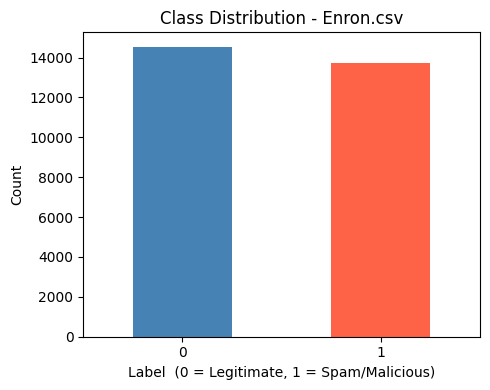

label
0    51.44
1    48.56
Name: proportion, dtype: float64


In [23]:
fig, ax = plt.subplots(figsize=(5, 4))
nlp_final['label'].value_counts().plot(kind='bar', color=['steelblue', 'tomato'], ax=ax)
ax.set_title('Class Distribution - Enron.csv')
ax.set_xlabel('Label  (0 = Legitimate, 1 = Spam/Malicious)')
ax.set_ylabel('Count')
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
plt.tight_layout()
plt.show()

print(nlp_final['label'].value_counts(normalize=True).mul(100).round(2))

## 16. Save preprocessed dataset

In [24]:
OUT_DIR   = '/content/drive/MyDrive/Phishing_Email/final_dataset'
os.makedirs(OUT_DIR, exist_ok=True)

save_path = f'{OUT_DIR}/Enron_preprocessed.csv'
nlp_final.to_csv(save_path, index=False)
print("Saved:", save_path, " | shape:", nlp_final.shape)

clean_ids = df['record_id'].tolist() if 'record_id' in df.columns else df.index.tolist()
ids_path  = f'{OUT_DIR}/enron_clean_ids.csv'
pd.DataFrame({'record_id': clean_ids}).to_csv(ids_path, index=False)
print(f"Exported {len(clean_ids):,} clean record IDs → {ids_path}")

Saved: /content/drive/MyDrive/Phishing_Email/final_dataset/Enron_preprocessed.csv  | shape: (28256, 10)
Exported 28,256 clean record IDs → /content/drive/MyDrive/Phishing_Email/final_dataset/enron_clean_ids.csv


## 17. Verify saved file

In [25]:
verify = pd.read_csv(
    '/content/drive/MyDrive/Phishing_Email/final_dataset/Enron_preprocessed.csv'
)
print("Loaded shape :", verify.shape)
print("Columns      :", verify.columns.tolist())
print("Label dist   :\n", verify['label'].value_counts())
print("Missing vals :\n", verify.isnull().sum())
print("Dtypes       :\n", verify.dtypes)
verify.head(2)

Loaded shape : (28256, 10)
Columns      : ['label', 'clean_text', 'word_count', 'avg_word_length', 'url_like_count', 'text_entropy', 'action_density', 'has_attachment', 'repeated_char_patterns', 'writing_error_total']
Label dist   :
 label
0    14536
1    13720
Name: count, dtype: int64
Missing vals :
 label                     0
clean_text                1
word_count                0
avg_word_length           0
url_like_count            0
text_entropy              0
action_density            0
has_attachment            0
repeated_char_patterns    0
writing_error_total       0
dtype: int64
Dtypes       :
 label                       int64
clean_text                 object
word_count                  int64
avg_word_length           float64
url_like_count              int64
text_entropy              float64
action_density            float64
has_attachment              int64
repeated_char_patterns      int64
writing_error_total         int64
dtype: object


,label,clean_text,word_count,avg_word_length,url_like_count,text_entropy,action_density,has_attachment,repeated_char_patterns,writing_error_total
0,0,see attached file hplno xl hplno xl,7,4.142857,0,4.112720,0.133333,1,0,12
1,0,forwarded sabrae zajac hou ect pm enron capita...,144,4.944444,0,4.604621,0.053991,0,1,16
